<a href="https://colab.research.google.com/github/mousmibara/DMPM-Lab.py/blob/main/DMPMLab8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Install Required Libraries
We need `scikit-learn-extra` for the `KMedoids` algorithm, as standard `scikit-learn` only includes `KMeans`.

In [ ]:
!pip install scikit-learn-extra

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 12.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2154567 sha256=6a0558b9b8380adc30ff8e31952d498e7f1f49ab245fb5ca5abbd1b2f6e3bb94
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra


### 2. Generate Synthetic Data
We will generate a 2D dataset with distinct isotropic Gaussian blobs and introduce some outliers to see how K-Means and K-Medoids handle them differently.

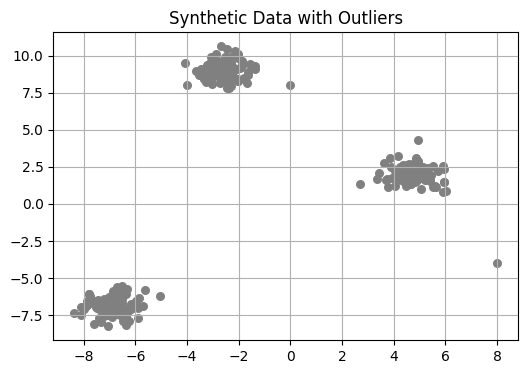

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# Generate synthetic data
X, y = make_blobs(n_samples=300, centers=3, cluster_std=0.60, random_state=42)

# Introduce some extreme outliers to demonstrate the robustness of K-Medoids
outliers = np.array([[-4, 8], [8, -4], [0, 8]])
X = np.vstack([X, outliers])

# Visualize raw data
plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], s=30, color='gray')
plt.title('Synthetic Data with Outliers')
plt.grid(True)
plt.show()

### 3. Apply K-Means and K-Medoids and Compare Results
Now we train both algorithms using 3 clusters and visualize how outliers affect their final cluster centers.

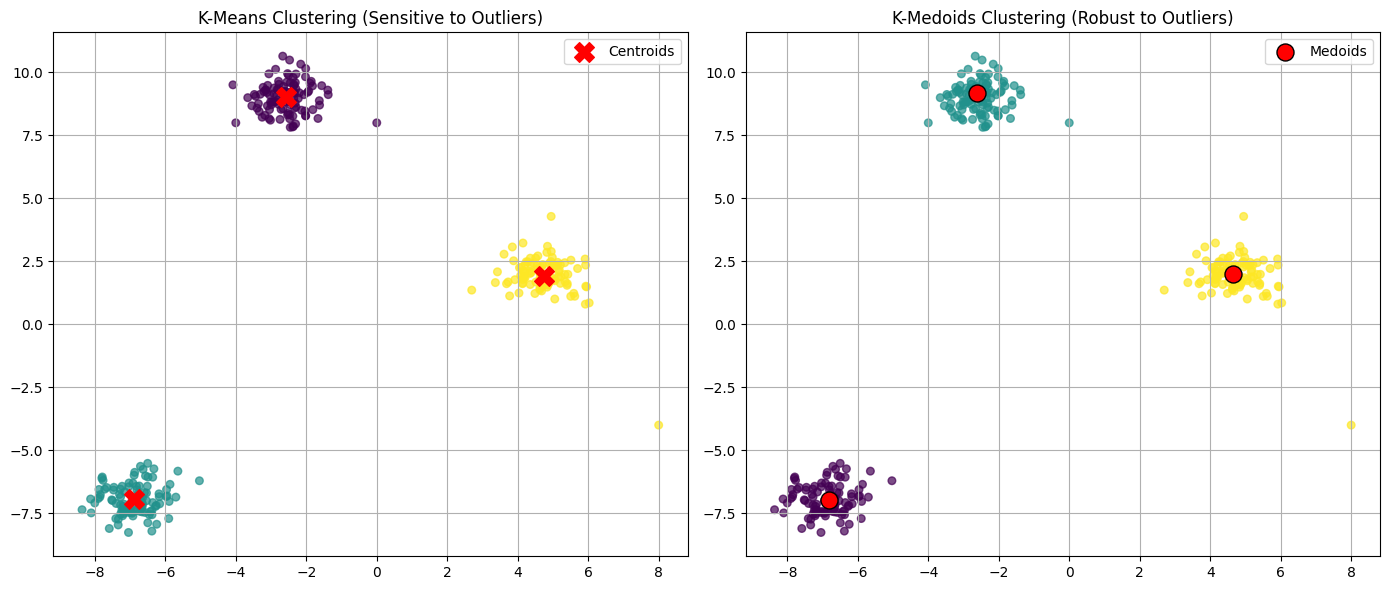

In [ ]:
from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids

# Apply K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
kmeans_labels = kmeans.fit_predict(X)
kmeans_centers = kmeans.cluster_centers_

# Apply K-Medoids
kmedoids = KMedoids(n_clusters=3, random_state=42)
kmedoids_labels = kmedoids.fit_predict(X)
kmedoids_centers = kmedoids.cluster_centers_

# Plotting the comparisons
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# K-Means plot
axes[0].scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='viridis', s=30, alpha=0.7)
axes[0].scatter(kmeans_centers[:, 0], kmeans_centers[:, 1], c='red', marker='X', s=200, label='Centroids')
axes[0].set_title('K-Means Clustering (Sensitive to Outliers)')
axes[0].grid(True)
axes[0].legend()

# K-Medoids plot
axes[1].scatter(X[:, 0], X[:, 1], c=kmedoids_labels, cmap='viridis', s=30, alpha=0.7)
axes[1].scatter(kmedoids_centers[:, 0], kmedoids_centers[:, 1], c='red', marker='o', edgecolors='black', s=150, label='Medoids')
axes[1].set_title('K-Medoids Clustering (Robust to Outliers)')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()